# FER2013: ViT, EfficientNet-B2, and ResNet-50

This notebook runs three independent, reproducible image-classification experiments. It uses the dataset, training, model, evaluation, and output settings in `config.yaml`. Validation data controls checkpoint selection; the held-out test set is evaluated only after every enabled model has been trained and selected.

**Default input:** the FER2013 CSV with the official `Training`, `PublicTest`, and `PrivateTest` partitions. The image-folder mode is also supported. The notebook does not load CK+, CREMA-D, or RAVDESS: these are outside the scope of this FER2013 facial-image comparison.

Run the cells from top to bottom. The default full run may take hours and pretrained weights may need to be downloaded. Set `run.smoke_test: true` in YAML for a small software check; smoke-test metrics are not research results.

`build_notebook.py` is not needed to run this notebook; the notebook reads `config.yaml` directly. The adjacent `build_notebook.py` is currently empty and is not used by this workflow.


In [8]:
from __future__ import annotations

import copy
import json
import random
import time
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import yaml
from PIL import Image
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Dataset
from torchvision import models, transforms
from tqdm.auto import tqdm


def find_config():
    for candidate in (Path.cwd(), *Path.cwd().parents):
        path = candidate / "config.yaml"
        if path.is_file():
            return path.resolve()
    raise FileNotFoundError(
        f"config.yaml was not found from working directory {Path.cwd()}. "
        "Start Jupyter in the project folder or set the notebook working directory there."
    )


CONFIG_PATH = find_config()
with CONFIG_PATH.open("r", encoding="utf-8") as stream:
    CONFIG = yaml.safe_load(stream)
PROJECT_ROOT = CONFIG_PATH.parent
LABELS = list(CONFIG["labels"])
NUM_CLASSES = len(LABELS)
SEED = int(CONFIG["dataset"]["random_seed"])
SMOKE = bool(CONFIG["run"]["smoke_test"])
RESUME_RUN_ID = str(CONFIG["outputs"].get("resume_run_id", "")).strip()
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

if NUM_CLASSES != 7 or len(set(LABELS)) != NUM_CLASSES:
    raise ValueError("config.yaml must define seven unique FER2013 labels in output-index order.")
if CONFIG["training"]["selection_metric"] not in {"val_macro_f1", "val_accuracy", "val_loss"}:
    raise ValueError("selection_metric must be val_macro_f1, val_accuracy, or val_loss.")

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True

print(f"Configuration: {CONFIG_PATH}")
print(f"Device: {DEVICE}; smoke test: {SMOKE}; labels: {LABELS}")


Configuration: C:\Users\Shahzaib Hussain\Desktop\Shahzaib Hussain\FYP\Emotion Detection through Voice and Face\config.yaml
Device: cpu; smoke test: False; labels: ['angry', 'disgust', 'fear', 'happy', 'sad', 'surprise', 'neutral']


## 1. Dataset loading and split integrity

CSV mode retains FER2013's official split semantics: `Training` is fitting data, `PublicTest` is validation, and `PrivateTest` is untouched until final testing. Image-folder mode stratifies the training folder into train/validation and uses its separate test folder. Input paths come only from YAML.


In [9]:
def _canonical_usage(value):
    key = str(value).strip().lower().replace("_", "").replace(" ", "")
    mapping = {
        "training": "train",
        "publictest": "validation",
        "privatetest": "test",
    }
    if key not in mapping:
        raise ValueError(f"Unexpected FER2013 Usage value {value!r}; expected Training/PublicTest/PrivateTest.")
    return mapping[key]


def load_records():
    dataset_cfg = CONFIG["dataset"]
    mode = str(dataset_cfg["format"]).strip().lower()
    if mode == "csv":
        csv_path = Path(dataset_cfg["csv_path"]).expanduser()
        if not csv_path.is_absolute():
            csv_path = (PROJECT_ROOT / csv_path).resolve()
        if not csv_path.is_file():
            raise FileNotFoundError(f"Configured FER2013 CSV does not exist: {csv_path}")
        frame = pd.read_csv(csv_path)
        required = {"emotion", "pixels", "Usage"}
        missing = required.difference(frame.columns)
        if missing:
            raise ValueError(f"{csv_path} is missing required columns: {sorted(missing)}")
        try:
            frame["emotion"] = frame["emotion"].astype(int)
        except (TypeError, ValueError) as exc:
            raise ValueError("FER2013 emotion column must contain integer class IDs 0 through 6.") from exc
        if not frame["emotion"].between(0, NUM_CLASSES - 1).all():
            raise ValueError("FER2013 emotion IDs must be in the range 0 through 6.")
        frame["split"] = frame["Usage"].map(_canonical_usage)
        records = {"train": [], "validation": [], "test": []}
        for label, pixels, split in zip(frame["emotion"], frame["pixels"], frame["split"]):
            if not isinstance(pixels, str) or not pixels.strip():
                raise ValueError("FER2013 pixels contains an empty or non-text row.")
            records[split].append((pixels, int(label)))
        del frame
        if not all(records.values()):
            raise ValueError(f"One or more official CSV splits are empty: { {k: len(v) for k, v in records.items()} }")
        return records, {"format": "csv", "source": str(csv_path)}

    if mode == "imagefolder":
        from torchvision.datasets import ImageFolder

        root = Path(dataset_cfg["image_root"]).expanduser()
        if not root.is_absolute():
            root = (PROJECT_ROOT / root).resolve()
        train_path = root / dataset_cfg.get("train_dir", "train")
        test_path = root / dataset_cfg.get("test_dir", "test")
        if not train_path.is_dir() or not test_path.is_dir():
            raise FileNotFoundError(f"Expected train and test class folders under {root}")
        raw_train = ImageFolder(str(train_path))
        raw_test = ImageFolder(str(test_path))
        name_to_label = {name.lower(): index for index, name in enumerate(LABELS)}
        for folder in (raw_train, raw_test):
            absent = set(folder.classes).difference(name_to_label)
            if absent:
                raise ValueError(f"Class folders do not match config.yaml labels: {sorted(absent)}")
        train_all = [(path, name_to_label[raw_train.classes[class_id].lower()])
                     for path, class_id in raw_train.samples]
        test = [(path, name_to_label[raw_test.classes[class_id].lower()])
                for path, class_id in raw_test.samples]
        if len(train_all) < 2 or not test:
            raise ValueError("Image-folder dataset must contain at least two training images and a non-empty test set.")
        fraction = float(dataset_cfg["validation_fraction"])
        if not 0 < fraction < 1:
            raise ValueError("dataset.validation_fraction must be strictly between 0 and 1.")
        train, validation = train_test_split(
            train_all,
            test_size=fraction,
            random_state=SEED,
            stratify=[label for _, label in train_all],
        )
        return {
            "train": list(train),
            "validation": list(validation),
            "test": test,
        }, {"format": "imagefolder", "source": str(root)}

    raise ValueError("dataset.format must be 'csv' or 'imagefolder'.")


def cap_records(records, maximum, seed):
    if maximum is None or len(records) <= maximum:
        return records
    return random.Random(seed).sample(records, maximum)


RECORDS, DATASET_INFO = load_records()
if SMOKE:
    RECORDS = {
        "train": cap_records(RECORDS["train"], CONFIG["run"]["smoke_train_samples"], SEED),
        "validation": cap_records(RECORDS["validation"], CONFIG["run"]["smoke_validation_samples"], SEED + 1),
        "test": cap_records(RECORDS["test"], CONFIG["run"]["smoke_test_samples"], SEED + 2),
    }
if any(not RECORDS[split] for split in ("train", "validation", "test")):
    raise ValueError("All train, validation, and test splits must be non-empty.")

SPLIT_SIZES = {split: len(rows) for split, rows in RECORDS.items()}
SPLIT_LABEL_COUNTS = {
    split: {
        LABELS[index]: int(sum(1 for _, label in rows if label == index))
        for index in range(NUM_CLASSES)
    }
    for split, rows in RECORDS.items()
}
print(f"Dataset: {DATASET_INFO}")
print(f"Split sizes: {SPLIT_SIZES}")
print(f"Split label counts: {SPLIT_LABEL_COUNTS}")


Dataset: {'format': 'csv', 'source': 'C:\\Users\\Shahzaib Hussain\\Desktop\\Shahzaib Hussain\\FYP\\Datasets\\Facial Dataset\\FER2013 CSV\\fer2013.csv'}
Split sizes: {'train': 28709, 'validation': 3589, 'test': 3589}
Split label counts: {'train': {'angry': 3995, 'disgust': 436, 'fear': 4097, 'happy': 7215, 'sad': 4830, 'surprise': 3171, 'neutral': 4965}, 'validation': {'angry': 467, 'disgust': 56, 'fear': 496, 'happy': 895, 'sad': 653, 'surprise': 415, 'neutral': 607}, 'test': {'angry': 491, 'disgust': 55, 'fear': 528, 'happy': 879, 'sad': 594, 'surprise': 416, 'neutral': 626}}


## 2. Image preprocessing and model definitions

All backbones produce seven logits in the configured label order and use their configured input size and channel normalization. The optional local ViT checkpoint is loaded strictly; if absent, the explicit torchvision ImageNet weight setting is used. Pretrained weights are disabled automatically in smoke mode to keep that check independent of network downloads.


In [10]:
class FERDataset(Dataset):
    def __init__(self, records, image_size, training=False, input_format=None, model_key=None):
        self.records = records
        self.input_format = input_format or DATASET_INFO["format"]
        model_cfg = CONFIG["models"].get(model_key, {}) if model_key else {}
        mean = model_cfg.get("normalization_mean", CONFIG["dataset"]["normalization_mean"])
        std = model_cfg.get("normalization_std", CONFIG["dataset"]["normalization_std"])
        if len(mean) != 3 or len(std) != 3 or any(float(value) <= 0 for value in std):
            raise ValueError(f"Invalid three-channel normalization settings for {model_key or 'dataset'}.")
        augmentation = CONFIG["training"]["augmentation"]
        extra_transforms = []
        if training and augmentation["horizontal_flip"]:
            extra_transforms.append(transforms.RandomHorizontalFlip(p=0.5))
        if training and float(augmentation["rotation_degrees"]) > 0:
            extra_transforms.append(
                transforms.RandomRotation(degrees=float(augmentation["rotation_degrees"]))
            )
        self.transform = transforms.Compose(
            [
                transforms.Resize((image_size, image_size)),
                *extra_transforms,
                transforms.ToTensor(),
                transforms.Normalize(mean=mean, std=std),
            ]
        )

    def __len__(self):
        return len(self.records)

    def __getitem__(self, index):
        source, label = self.records[index]
        if self.input_format == "csv":
            pixels = np.fromstring(source, dtype=np.uint8, sep=" ")
            if pixels.size != 48 * 48:
                raise ValueError(f"FER2013 row {index} has {pixels.size} pixels; expected 2304.")
            image = Image.fromarray(pixels.reshape(48, 48), mode="L").convert("RGB")
        else:
            with Image.open(source) as opened:
                image = opened.convert("RGB")
        return self.transform(image), int(label)


def make_loader(records, image_size, batch_size, training, model_key):
    dataset = FERDataset(records, image_size=image_size, training=training, model_key=model_key)
    return DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=training,
        num_workers=int(CONFIG["dataset"]["num_workers"]),
        pin_memory=bool(CONFIG["dataset"]["pin_memory"] and DEVICE.type == "cuda"),
        persistent_workers=int(CONFIG["dataset"]["num_workers"]) > 0,
    )


def build_model(model_key, load_pretrained=True):
    model_cfg = CONFIG["models"][model_key]
    architecture = model_cfg["architecture"]
    face_checkpoint = str(model_cfg.get("face_checkpoint", "")).strip()
    use_pretrained = (
        bool(model_cfg.get("pretrained", True))
        and load_pretrained
        and not SMOKE
        and not (architecture == "vit_b_16" and face_checkpoint)
    )

    if architecture == "vit_b_16":
        model_fn, weights_type = models.vit_b_16, models.ViT_B_16_Weights
    elif architecture == "efficientnet_b2":
        model_fn, weights_type = models.efficientnet_b2, models.EfficientNet_B2_Weights
    elif architecture == "resnet50":
        model_fn, weights_type = models.resnet50, models.ResNet50_Weights
    else:
        raise ValueError(f"Unsupported architecture {architecture!r} for {model_key}.")

    weights = None
    if use_pretrained:
        weight_name = model_cfg.get("imagenet_weights", "DEFAULT")
        try:
            weights = getattr(weights_type, weight_name)
        except AttributeError as exc:
            raise ValueError(f"Invalid torchvision weight {weight_name!r} for {architecture}.") from exc
    model = model_fn(weights=weights)

    if architecture == "vit_b_16":
        in_features = model.heads.head.in_features
        model.heads.head = nn.Linear(in_features, NUM_CLASSES)
        if face_checkpoint and load_pretrained and not SMOKE:
            checkpoint_path = Path(face_checkpoint).expanduser()
            if not checkpoint_path.is_absolute():
                checkpoint_path = (PROJECT_ROOT / checkpoint_path).resolve()
            if not checkpoint_path.is_file():
                raise FileNotFoundError(f"Configured face-pretrained ViT checkpoint not found: {checkpoint_path}")
            payload = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
            if isinstance(payload, dict) and "state_dict" in payload:
                payload = payload["state_dict"]
            elif isinstance(payload, dict) and "model" in payload:
                payload = payload["model"]
            if not isinstance(payload, dict):
                raise ValueError("ViT checkpoint must be a state_dict or contain a state_dict under 'state_dict'/'model'.")
            state = {key.removeprefix("module."): value for key, value in payload.items()}
            try:
                model.load_state_dict(state, strict=True)
            except RuntimeError as exc:
                raise ValueError(
                    f"Face checkpoint is not an exact compatible ViT-B/16 with a seven-class head: {checkpoint_path}"
                ) from exc
    elif architecture == "efficientnet_b2":
        in_features = model.classifier[1].in_features
        model.classifier[1] = nn.Linear(in_features, NUM_CLASSES)
    else:
        model.fc = nn.Linear(model.fc.in_features, NUM_CLASSES)
    return model


ENABLED_MODELS = [
    key for key, settings in CONFIG["models"].items() if settings.get("enabled", False)
]
if not ENABLED_MODELS:
    raise ValueError("Enable at least one model in config.yaml.")
print("Enabled models:", ENABLED_MODELS)


Enabled models: ['vit', 'efficientnet_b2', 'resnet50']


## 3. Training and validation-based checkpoint selection

Every model has a separate best checkpoint, resumable last-epoch checkpoint, and epoch history. Training uses focal loss with configurable gamma; existing saved training/test outputs predate this loss change and must not be cited as focal-loss results. Rerun training and final evaluation to generate valid focal-loss metrics. The training loop never reads test records. The best checkpoint is chosen only by the configured validation metric; early stopping also observes validation performance. To resume, set `outputs.resume_run_id` to the existing run directory name and keep the saved configuration unchanged.


In [11]:
def save_checkpoint(payload, checkpoint_path):
    temporary_path = checkpoint_path.with_name(f".{checkpoint_path.name}.tmp")
    torch.save(payload, temporary_path)
    temporary_path.replace(checkpoint_path)


def load_training_checkpoint(checkpoint_path):
    try:
        payload = torch.load(checkpoint_path, map_location=DEVICE, weights_only=True)
    except TypeError:
        payload = torch.load(checkpoint_path, map_location=DEVICE)
    if not isinstance(payload, dict):
        raise ValueError(f"Training checkpoint must contain a dictionary: {checkpoint_path}")
    return payload


class FocalLoss(nn.Module):
    def __init__(self, weight=None, gamma=2.0, label_smoothing=0.0, reduction="mean"):
        super().__init__()
        if gamma < 0:
            raise ValueError("Focal-loss gamma must be non-negative.")
        if not 0.0 <= label_smoothing < 1.0:
            raise ValueError("label_smoothing must be in the range [0, 1).")
        if reduction not in {"none", "mean", "sum"}:
            raise ValueError("reduction must be 'none', 'mean', or 'sum'.")
        if weight is not None and weight.ndim != 1:
            raise ValueError("Focal-loss class weights must be a one-dimensional tensor.")
        self.register_buffer("weight", weight)
        self.gamma = float(gamma)
        self.label_smoothing = float(label_smoothing)
        self.reduction = reduction

    def forward(self, logits, targets):
        if logits.ndim != 2 or targets.ndim != 1 or logits.size(0) != targets.size(0):
            raise ValueError("FocalLoss expects logits shaped [batch, classes] and targets shaped [batch].")
        targets = targets.long()
        log_probs = torch.nn.functional.log_softmax(logits.float(), dim=1)
        log_pt = log_probs.gather(1, targets.unsqueeze(1)).squeeze(1)
        base_loss = -log_pt
        if self.label_smoothing:
            smooth_loss = -log_probs.mean(dim=1)
            base_loss = (1.0 - self.label_smoothing) * base_loss + self.label_smoothing * smooth_loss
        loss = (1.0 - log_pt.exp()).pow(self.gamma) * base_loss
        if self.weight is not None:
            target_weights = self.weight[targets]
            loss = loss * target_weights
        if self.reduction == "none":
            return loss
        if self.reduction == "sum":
            return loss.sum()
        normalizer = target_weights.sum() if self.weight is not None else loss.new_tensor(float(loss.numel()))
        return loss.sum() / normalizer.clamp_min(torch.finfo(loss.dtype).eps)


LOSS_CONFIG = {
    "name": str(CONFIG["training"].get("loss_function", "focal")).strip().lower(),
    "gamma": float(CONFIG["training"].get("focal_gamma", 2.0)),
    "label_smoothing": float(CONFIG["training"]["label_smoothing"]),
    "class_weighted": bool(CONFIG["training"]["class_weighted_loss"]),
}
if LOSS_CONFIG["name"] != "focal":
    raise ValueError("This notebook currently supports focal loss only.")


def make_criterion():
    class_weights = None
    if CONFIG["training"]["class_weighted_loss"]:
        counts = np.bincount([label for _, label in RECORDS["train"]], minlength=NUM_CLASSES)
        weights = len(RECORDS["train"]) / (NUM_CLASSES * np.maximum(counts, 1))
        class_weights = torch.tensor(weights, dtype=torch.float32, device=DEVICE)
    return FocalLoss(
        weight=class_weights,
        gamma=LOSS_CONFIG["gamma"],
        label_smoothing=LOSS_CONFIG["label_smoothing"],
    ).to(DEVICE)


def evaluate_loader(model, loader, criterion, device):
    model.eval()
    loss_sum, sample_count, targets, predictions = 0.0, 0, [], []
    with torch.inference_mode():
        for images, labels in loader:
            images, labels = images.to(device, non_blocking=True), labels.to(device, non_blocking=True)
            logits = model(images)
            batch_size = int(labels.size(0))
            loss_sum += float(criterion(logits, labels).item()) * batch_size
            sample_count += batch_size
            targets.extend(labels.cpu().tolist())
            predictions.extend(logits.argmax(dim=1).cpu().tolist())
    return {
        "loss": loss_sum / sample_count,
        "accuracy": float(accuracy_score(targets, predictions)),
        "macro_f1": float(f1_score(targets, predictions, labels=list(range(NUM_CLASSES)),
                                   average="macro", zero_division=0)),
    }


def train_one_model(model_key, model_output):
    model_cfg = CONFIG["models"][model_key]
    image_size = int(model_cfg["input_size"])
    batch_size = int(model_cfg.get("batch_size", CONFIG["training"]["batch_size"]))
    train_loader = make_loader(RECORDS["train"], image_size, batch_size, training=True, model_key=model_key)
    validation_loader = make_loader(RECORDS["validation"], image_size, batch_size, training=False, model_key=model_key)
    model = build_model(model_key, load_pretrained=not bool(RESUME_RUN_ID)).to(DEVICE)

    criterion = make_criterion()
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=float(CONFIG["training"]["learning_rate"]),
        weight_decay=float(CONFIG["training"]["weight_decay"]),
    )
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="min",
        factor=float(CONFIG["training"]["scheduler_factor"]),
        patience=int(CONFIG["training"]["scheduler_patience"]),
    )
    amp_enabled = bool(CONFIG["training"]["use_amp"] and DEVICE.type == "cuda")
    scaler = torch.amp.GradScaler("cuda", enabled=amp_enabled)
    epochs = int(CONFIG["run"]["smoke_epochs"] if SMOKE else CONFIG["training"]["epochs"])
    patience = int(CONFIG["training"]["patience"])
    selection_metric = CONFIG["training"]["selection_metric"]
    minimize = selection_metric == "val_loss"
    best_value = float("inf") if minimize else -float("inf")
    best_epoch, epochs_without_improvement = 0, 0
    checkpoint_path = model_output / "best_model.pt"
    last_checkpoint_path = model_output / "last_checkpoint.pt"
    history = []
    start_epoch = 1
    previous_training_seconds = 0.0
    started = time.perf_counter()
    if RESUME_RUN_ID and last_checkpoint_path.is_file():
        resume = load_training_checkpoint(last_checkpoint_path)
        expected = {
            "model_key": model_key,
            "labels": LABELS,
            "seed": SEED,
            "selection_metric": selection_metric,
            "model_config": model_cfg,
            "split_sizes": SPLIT_SIZES,
            "loss_config": LOSS_CONFIG,
        }
        mismatches = [key for key, value in expected.items() if resume.get(key) != value]
        if mismatches:
            raise ValueError(f"Cannot resume {model_key}; checkpoint metadata differs: {mismatches}")
        model.load_state_dict(resume["model_state_dict"], strict=True)
        optimizer.load_state_dict(resume["optimizer_state_dict"])
        scheduler.load_state_dict(resume["scheduler_state_dict"])
        scaler.load_state_dict(resume["scaler_state_dict"])
        history = resume["history"]
        best_value = float(resume["best_value"])
        best_epoch = int(resume["best_epoch"])
        epochs_without_improvement = int(resume["epochs_without_improvement"])
        start_epoch = int(resume["epoch"]) + 1
        previous_training_seconds = float(resume.get("training_seconds", 0.0))
        random.setstate(resume["python_rng_state"])
        np.random.set_state((
            "MT19937",
            np.asarray(resume["numpy_rng_keys"], dtype=np.uint32),
            int(resume["numpy_rng_position"]),
            int(resume["numpy_rng_has_gauss"]),
            float(resume["numpy_rng_cached_gaussian"]),
        ))
        torch.set_rng_state(resume["torch_rng_state"].cpu())
        if DEVICE.type == "cuda" and resume.get("cuda_rng_state_all"):
            torch.cuda.set_rng_state_all(resume["cuda_rng_state_all"])
        print(f"Resuming {model_key} at epoch {start_epoch} from {last_checkpoint_path}.")

    for epoch in range(start_epoch, epochs + 1):
        model.train()
        epoch_loss_sum, correct, seen = 0.0, 0, 0
        progress = tqdm(train_loader, desc=f"{model_key} {epoch}/{epochs}", leave=False)
        for images, labels in progress:
            images, labels = images.to(DEVICE, non_blocking=True), labels.to(DEVICE, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type=DEVICE.type, enabled=amp_enabled):
                logits = model(images)
                loss = criterion(logits, labels)
            scaler.scale(loss).backward()
            if CONFIG["training"]["gradient_clip_norm"]:
                scaler.unscale_(optimizer)
                nn.utils.clip_grad_norm_(model.parameters(), float(CONFIG["training"]["gradient_clip_norm"]))
            scaler.step(optimizer)
            scaler.update()
            epoch_loss_sum += float(loss.item()) * int(labels.size(0))
            correct += int((logits.argmax(dim=1) == labels).sum().item())
            seen += int(labels.size(0))
            progress.set_postfix(loss=f"{loss.item():.4f}")

        validation = evaluate_loader(model, validation_loader, criterion, DEVICE)
        scheduler.step(validation["loss"])
        row = {
            "epoch": epoch,
            "train_loss": epoch_loss_sum / max(seen, 1),
            "train_accuracy": correct / max(seen, 1),
            "val_loss": validation["loss"],
            "val_accuracy": validation["accuracy"],
            "val_macro_f1": validation["macro_f1"],
            "learning_rate": optimizer.param_groups[0]["lr"],
        }
        history.append(row)
        print(
            f"{model_key} epoch {epoch}: train_loss={row['train_loss']:.4f}, "
            f"val_loss={row['val_loss']:.4f}, val_macro_f1={row['val_macro_f1']:.4f}"
        )
        value = row[selection_metric]
        improved = value < best_value if minimize else value > best_value
        if improved:
            best_value, best_epoch, epochs_without_improvement = value, epoch, 0
            save_checkpoint(
                {
                    "model_key": model_key,
                    "model_state_dict": model.state_dict(),
                    "labels": LABELS,
                    "best_epoch": best_epoch,
                    "selection_metric": selection_metric,
                    "selection_value": best_value,
                    "seed": SEED,
                    "loss_config": LOSS_CONFIG,
                },
                checkpoint_path,
            )
        else:
            epochs_without_improvement += 1
        save_checkpoint(
            {
                "model_key": model_key,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "scheduler_state_dict": scheduler.state_dict(),
                "scaler_state_dict": scaler.state_dict(),
                "labels": LABELS,
                "seed": SEED,
                "selection_metric": selection_metric,
                "model_config": model_cfg,
                "loss_config": LOSS_CONFIG,
                "split_sizes": SPLIT_SIZES,
                "epoch": epoch,
                "history": history,
                "best_value": best_value,
                "best_epoch": best_epoch,
                "epochs_without_improvement": epochs_without_improvement,
                "training_seconds": previous_training_seconds + time.perf_counter() - started,
                "python_rng_state": random.getstate(),
                "numpy_rng_keys": np.random.get_state()[1].tolist(),
                "numpy_rng_position": int(np.random.get_state()[2]),
                "numpy_rng_has_gauss": int(np.random.get_state()[3]),
                "numpy_rng_cached_gaussian": float(np.random.get_state()[4]),
                "torch_rng_state": torch.get_rng_state(),
                "cuda_rng_state_all": torch.cuda.get_rng_state_all() if DEVICE.type == "cuda" else [],
            },
            last_checkpoint_path,
        )
        if patience > 0 and epochs_without_improvement >= patience:
            print(f"Early stopping {model_key}: no validation improvement for {patience} epochs.")
            break

    pd.DataFrame(history).to_csv(model_output / "training_history.csv", index=False)
    history_frame = pd.DataFrame(history)
    figure, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].plot(history_frame["epoch"], history_frame["train_loss"], label="train")
    axes[0].plot(history_frame["epoch"], history_frame["val_loss"], label="validation")
    axes[0].set(xlabel="Epoch", ylabel="Focal loss", title=f"{model_key} loss")
    axes[0].legend()
    axes[1].plot(history_frame["epoch"], history_frame["val_macro_f1"], label="validation macro-F1")
    axes[1].set(xlabel="Epoch", ylabel="Macro-F1", title=f"{model_key} validation score")
    axes[1].legend()
    figure.tight_layout()
    figure.savefig(model_output / "training_history.png", dpi=160)
    plt.close(figure)
    elapsed = time.perf_counter() - started
    if not checkpoint_path.is_file():
        raise RuntimeError(f"No selected checkpoint was saved for {model_key}.")
    del model, optimizer, scheduler, scaler, train_loader, validation_loader
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return {
        "checkpoint_path": str(checkpoint_path),
        "history_path": str(model_output / "training_history.csv"),
        "best_epoch": best_epoch,
        "best_selection_value": float(best_value),
        "training_seconds": previous_training_seconds + elapsed,
    }


## 4. Train all models, then evaluate the held-out test set

This cell intentionally completes training and validation-based selection for every enabled model before any test evaluation. Test metrics are final reporting only and cannot affect weights or model selection. The saved outputs currently shown below were generated with cross-entropy before the focal-loss change; rerun this cell and the final evaluation cell before using any reported metrics.


In [12]:
OUTPUT_ROOT = Path(CONFIG["outputs"]["root"]).expanduser()
if not OUTPUT_ROOT.is_absolute():
    OUTPUT_ROOT = (PROJECT_ROOT / OUTPUT_ROOT).resolve()
if RESUME_RUN_ID:
    if Path(RESUME_RUN_ID).name != RESUME_RUN_ID or RESUME_RUN_ID in {".", ".."}:
        raise ValueError("outputs.resume_run_id must be a single existing run-directory name.")
    RUN_ID = RESUME_RUN_ID
    RUN_DIR = OUTPUT_ROOT / RUN_ID
    if not RUN_DIR.is_dir():
        raise FileNotFoundError(f"Cannot resume; run directory does not exist: {RUN_DIR}")
    saved_config_path = RUN_DIR / "config.yaml"
    if not saved_config_path.is_file():
        raise FileNotFoundError(f"Cannot resume; saved run configuration is missing: {saved_config_path}")
    saved_config = yaml.safe_load(saved_config_path.read_text(encoding="utf-8"))
    current_config = copy.deepcopy(CONFIG)
    saved_config.setdefault("outputs", {})["resume_run_id"] = ""
    current_config["outputs"]["resume_run_id"] = ""
    if saved_config != current_config:
        raise ValueError("Cannot resume: config.yaml differs from the configuration saved with this run.")
else:
    RUN_ID = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
    RUN_DIR = OUTPUT_ROOT / RUN_ID
    RUN_DIR.mkdir(parents=True, exist_ok=False)
    with (RUN_DIR / "config.yaml").open("w", encoding="utf-8") as stream:
        yaml.safe_dump(CONFIG, stream, sort_keys=False, allow_unicode=True)

metadata_path = RUN_DIR / "run_metadata.json"
if RESUME_RUN_ID:
    metadata = json.loads(metadata_path.read_text(encoding="utf-8"))
    metadata.setdefault("resume_events", []).append(datetime.now().astimezone().isoformat())
else:
    metadata = {
        "run_id": RUN_ID,
        "created_at": datetime.now().astimezone().isoformat(),
        "config_path": str(CONFIG_PATH),
        "dataset": DATASET_INFO,
        "split_sizes": SPLIT_SIZES,
        "split_label_counts": SPLIT_LABEL_COUNTS,
        "labels": LABELS,
        "seed": SEED,
        "device": str(DEVICE),
        "smoke_test": SMOKE,
    }
metadata_path.write_text(json.dumps(metadata, indent=2), encoding="utf-8")

EXPERIMENT_RESULTS = {}
for model_key in ENABLED_MODELS:
    model_dir = RUN_DIR / model_key
    model_dir.mkdir(parents=True, exist_ok=bool(RESUME_RUN_ID))
    EXPERIMENT_RESULTS[model_key] = train_one_model(model_key, model_dir)

print("Training and validation selection finished for all enabled models.")
print(json.dumps(EXPERIMENT_RESULTS, indent=2))


Downloading: "https://download.pytorch.org/models/vit_b_16-c867db91.pth" to C:\Users\Shahzaib Hussain/.cache\torch\hub\checkpoints\vit_b_16-c867db91.pth


100%|██████████| 330M/330M [02:17<00:00, 2.51MB/s] 


vit epoch 1: train_loss=0.7853, val_loss=0.6186, val_macro_f1=0.5145


vit epoch 2: train_loss=0.5811, val_loss=0.5947, val_macro_f1=0.5632


vit epoch 3: train_loss=0.5170, val_loss=0.5437, val_macro_f1=0.6096


vit epoch 4: train_loss=0.4647, val_loss=0.5568, val_macro_f1=0.5968


... (64 outputs left out)

resnet50 epoch 19: train_loss=0.0108, val_loss=0.9913, val_macro_f1=0.6842


resnet50 epoch 20: train_loss=0.0089, val_loss=0.9884, val_macro_f1=0.6858


resnet50 epoch 21: train_loss=0.0084, val_loss=0.9989, val_macro_f1=0.6859


resnet50 epoch 22: train_loss=0.0072, val_loss=1.0175, val_macro_f1=0.6850
Early stopping resnet50: no validation improvement for 7 epochs.
Training and validation selection finished for all enabled models.
{
  "vit": {
    "checkpoint_path": "C:\\Users\\Shahzaib Hussain\\Desktop\\Shahzaib Hussain\\FYP\\Emotion Detection through Voice and Face\\outputs\\facial_emotion_experiments\\20261021_030640_856570\\vit\\best_model.pt",
    "history_path": "C:\\Users\\Shahzaib Hussain\\Desktop\\Shahzaib Hussain\\FYP\\Emotion Detection through Voice and Face\\outputs\\facial_emotion_experiments\\20261021_030640_856570\\vit\\training_history.csv",
    "best_epoch": 18,
    "best_selection_value": 0.6930816031496285,
    "training_seconds": 164916.7689511
  },
  "efficientnet_b2": {
    "checkpoint_path": "C:\\Users\\Shahzaib Hussain\\Desktop\\Shahzaib Hussain\\FYP\\Emotion Detection through Voice and Face\\outputs\\facial_emotion_experiments\\20261021_030640_856570\\efficientnet_b2\\best_model.pt",


## 5. Final test metrics, CPU latency, and optional exports

Metrics include accuracy, macro-F1, per-class precision/recall/F1, and a confusion matrix. Latency is measured on the CPU for one already-preprocessed input tensor after warmup; preprocessing and camera/application overhead are excluded. These measurements are empirical, hardware-dependent observations.


Final test: vit: 100%|██████████| 113/113 [01:41<00:00,  1.12it/s]


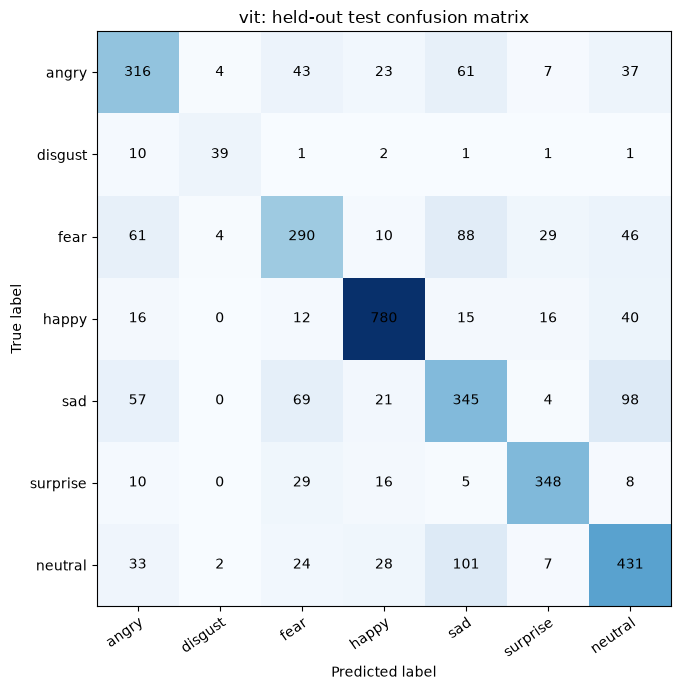

Final test: efficientnet_b2: 100%|██████████| 113/113 [00:26<00:00,  4.26it/s]


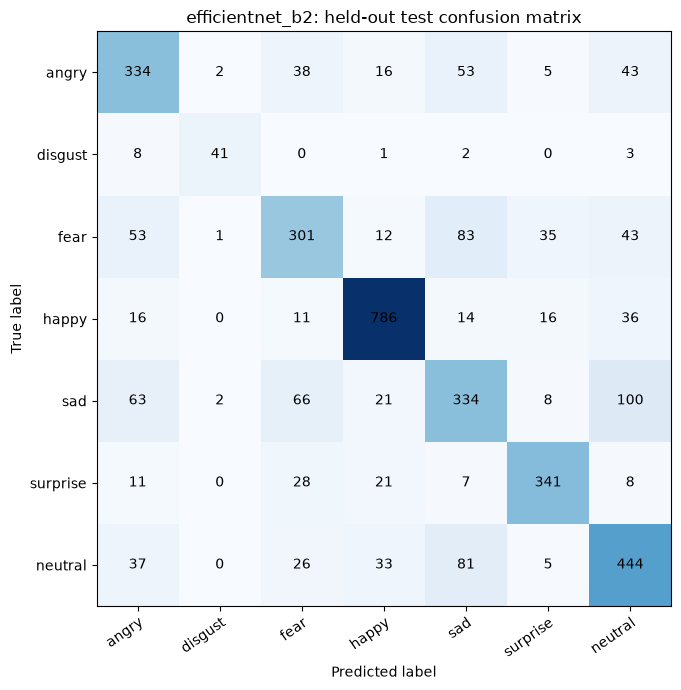

Final test: resnet50: 100%|██████████| 113/113 [00:43<00:00,  2.63it/s]


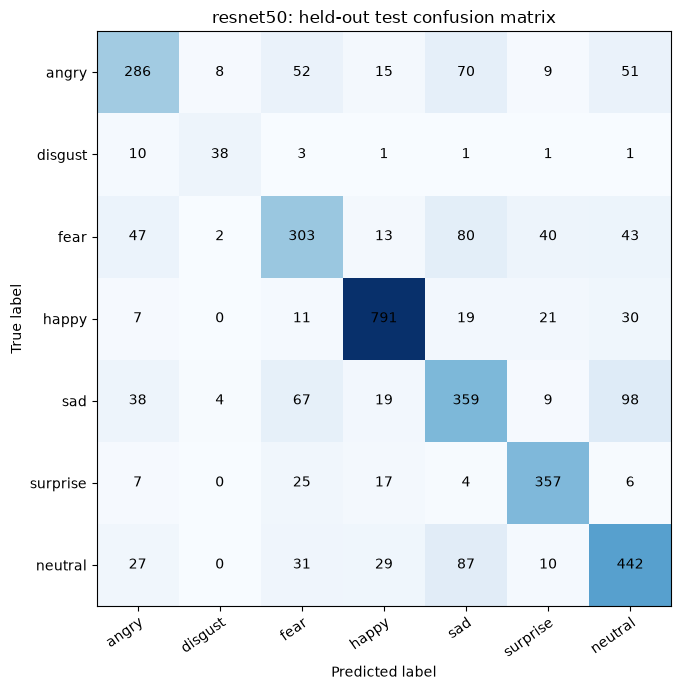

Complete. Results saved to: C:\Users\Shahzaib Hussain\Desktop\Shahzaib Hussain\FYP\Emotion Detection through Voice and Face\outputs\facial_emotion_experiments\20261021_030640_856570
{
  "vit": {
    "best_epoch": 18,
    "best_validation_value": 0.6930816031496285,
    "test_accuracy": 0.710225689607133,
    "test_macro_f1": 0.7050877226832947,
    "cpu_benchmark": {
      "latency_ms_per_image": 33.987198999966495,
      "throughput_images_per_second": 29.422842406077237
    }
  },
  "efficientnet_b2": {
    "best_epoch": 17,
    "best_validation_value": 0.7058475370853446,
    "test_accuracy": 0.7191418222346058,
    "test_macro_f1": 0.7203200830547185,
    "cpu_benchmark": {
      "latency_ms_per_image": 12.637863000272773,
      "throughput_images_per_second": 79.12730182139308
    }
  },
  "resnet50": {
    "best_epoch": 15,
    "best_validation_value": 0.6913627400074521,
    "test_accuracy": 0.7177486765115632,
    "test_macro_f1": 0.7040117209278479,
    "cpu_benchmark": {
    

In [13]:
def load_selected_model(model_key, checkpoint_path):
    model = build_model(model_key, load_pretrained=False)
    try:
        checkpoint = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
    except TypeError:
        checkpoint = torch.load(checkpoint_path, map_location="cpu")
    if checkpoint.get("labels") != LABELS:
        raise ValueError(f"Checkpoint label order differs from config for {model_key}.")
    model.load_state_dict(checkpoint["model_state_dict"], strict=True)
    return model


def benchmark_cpu(model, image_size):
    cpu_model = copy.deepcopy(model).to("cpu").eval()
    sample = torch.randn(1, 3, image_size, image_size)
    warmup = int(CONFIG["evaluation"]["latency_warmup"])
    iterations = int(CONFIG["evaluation"]["latency_iterations"])
    if warmup < 0 or iterations < 1:
        raise ValueError("Latency warmup must be non-negative and iterations must be positive.")
    with torch.inference_mode():
        for _ in range(warmup):
            cpu_model(sample)
        start = time.perf_counter()
        for _ in range(iterations):
            cpu_model(sample)
        elapsed = time.perf_counter() - start
    del cpu_model
    latency_ms = elapsed * 1000.0 / iterations
    return {"latency_ms_per_image": latency_ms, "throughput_images_per_second": 1000.0 / latency_ms}


def export_model(model, model_key, model_dir, image_size):
    export_cfg = CONFIG["evaluation"]
    export_results = {}
    if not export_cfg["export_torchscript"] and not export_cfg["export_onnx"]:
        return export_results
    cpu_model = copy.deepcopy(model).to("cpu").eval()
    sample = torch.randn(2, 3, image_size, image_size)
    with torch.inference_mode():
        reference = cpu_model(sample).cpu().numpy()
    if export_cfg["export_torchscript"]:
        traced = torch.jit.trace(cpu_model, sample, check_trace=False)
        traced.save(str(model_dir / "model_torchscript.pt"))
        with torch.inference_mode():
            actual = traced(sample).cpu().numpy()
        max_error = float(np.max(np.abs(reference - actual)))
        if not np.allclose(reference, actual, rtol=1e-4, atol=1e-5):
            raise RuntimeError(f"TorchScript output mismatch for {model_key}; max absolute error={max_error}.")
        export_results["torchscript"] = {"max_absolute_error": max_error}
    if export_cfg["export_onnx"]:
        try:
            import onnx
            import onnxruntime as ort
        except ImportError as exc:
            raise ImportError("ONNX export is enabled; install onnx and onnxruntime in this notebook kernel.") from exc
        torch.onnx.export(
            cpu_model,
            sample,
            str(model_dir / "model.onnx"),
            input_names=["images"],
            output_names=["logits"],
            dynamic_axes={"images": {0: "batch"}, "logits": {0: "batch"}},
            opset_version=int(export_cfg["onnx_opset"]),
        )
        onnx_model = onnx.load(str(model_dir / "model.onnx"))
        onnx.checker.check_model(onnx_model)
        session = ort.InferenceSession(str(model_dir / "model.onnx"), providers=["CPUExecutionProvider"])
        actual = session.run(["logits"], {"images": sample.numpy()})[0]
        max_error = float(np.max(np.abs(reference - actual)))
        if not np.allclose(reference, actual, rtol=1e-4, atol=1e-5):
            raise RuntimeError(f"ONNX output mismatch for {model_key}; max absolute error={max_error}.")
        export_results["onnx"] = {"max_absolute_error": max_error}
    del cpu_model
    return export_results


FINAL_RESULTS = {}
for model_key in ENABLED_MODELS:
    model_dir = RUN_DIR / model_key
    model_cfg = CONFIG["models"][model_key]
    image_size = int(model_cfg["input_size"])
    batch_size = int(model_cfg.get("batch_size", CONFIG["training"]["batch_size"]))
    test_loader = make_loader(RECORDS["test"], image_size, batch_size, training=False, model_key=model_key)
    model = load_selected_model(model_key, EXPERIMENT_RESULTS[model_key]["checkpoint_path"]).to(DEVICE).eval()
    all_targets, all_predictions, test_loss_sum, test_items = [], [], 0.0, 0
    criterion = make_criterion()
    with torch.inference_mode():
        for images, labels in tqdm(test_loader, desc=f"Final test: {model_key}"):
            images, labels = images.to(DEVICE, non_blocking=True), labels.to(DEVICE, non_blocking=True)
            logits = model(images)
            test_loss_sum += float(criterion(logits, labels).item()) * len(labels)
            test_items += len(labels)
            all_targets.extend(labels.cpu().tolist())
            all_predictions.extend(logits.argmax(dim=1).cpu().tolist())

    report = classification_report(
        all_targets,
        all_predictions,
        labels=list(range(NUM_CLASSES)),
        target_names=LABELS,
        output_dict=True,
        zero_division=0,
    )
    confusion = confusion_matrix(all_targets, all_predictions, labels=list(range(NUM_CLASSES)))
    test_metrics = {
        "loss_config": LOSS_CONFIG,
        "test_loss": test_loss_sum / test_items,
        "accuracy": float(accuracy_score(all_targets, all_predictions)),
        "macro_f1": float(f1_score(all_targets, all_predictions, labels=list(range(NUM_CLASSES)),
                                   average="macro", zero_division=0)),
        "classification_report": report,
        "confusion_matrix": confusion.tolist(),
        "best_epoch": EXPERIMENT_RESULTS[model_key]["best_epoch"],
        "selection_metric": CONFIG["training"]["selection_metric"],
        "best_selection_value": EXPERIMENT_RESULTS[model_key]["best_selection_value"],
    }
    if CONFIG["evaluation"]["benchmark_cpu"]:
        test_metrics["cpu_benchmark"] = benchmark_cpu(model, image_size)
    test_metrics["exports"] = export_model(model, model_key, model_dir, image_size)
    (model_dir / "final_test_metrics.json").write_text(
        json.dumps(test_metrics, indent=2), encoding="utf-8"
    )
    if CONFIG["outputs"]["save_predictions"]:
        pd.DataFrame(
            {
                "true_label_id": all_targets,
                "true_label": [LABELS[value] for value in all_targets],
                "predicted_label_id": all_predictions,
                "predicted_label": [LABELS[value] for value in all_predictions],
            }
        ).to_csv(model_dir / "test_predictions.csv", index=False)

    figure, axis = plt.subplots(figsize=(8, 7))
    axis.imshow(confusion, cmap="Blues")
    axis.set(
        xticks=np.arange(NUM_CLASSES),
        yticks=np.arange(NUM_CLASSES),
        xticklabels=LABELS,
        yticklabels=LABELS,
        xlabel="Predicted label",
        ylabel="True label",
        title=f"{model_key}: held-out test confusion matrix",
    )
    plt.setp(axis.get_xticklabels(), rotation=35, ha="right", rotation_mode="anchor")
    for row in range(NUM_CLASSES):
        for col in range(NUM_CLASSES):
            axis.text(col, row, str(confusion[row, col]), ha="center", va="center")
    figure.tight_layout()
    figure.savefig(model_dir / "test_confusion_matrix.png", dpi=160)
    plt.show()
    plt.close(figure)

    FINAL_RESULTS[model_key] = {**EXPERIMENT_RESULTS[model_key], **test_metrics}
    del model, test_loader
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

summary = {
    model_key: {
        "best_epoch": values["best_epoch"],
        "best_validation_value": values["best_selection_value"],
        "test_accuracy": values["accuracy"],
        "test_macro_f1": values["macro_f1"],
        "cpu_benchmark": values.get("cpu_benchmark"),
    }
    for model_key, values in FINAL_RESULTS.items()
}
(RUN_DIR / "final_summary.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")
print(f"Complete. Results saved to: {RUN_DIR}")
print(json.dumps(summary, indent=2))


## Interpretation and limitations

Compare models using the same split definitions and the recorded configuration. The validation-selected checkpoint is the one reported on the held-out test partition; do not repeatedly tune using that test result. Macro-F1 weights each class equally, while accuracy is frequency-weighted. Review per-class scores and the confusion matrix rather than relying on one aggregate number.

FER2013 has noisy labels, class imbalance, low-resolution grayscale faces, and demographic/collection limitations. ImageNet pretraining is not equivalent to facial-expression pretraining. For the ViT, only a compatible checkpoint explicitly supplied in YAML qualifies as the configured face-pretrained model; the ImageNet fallback is clearly recorded in the configuration. A single-image model-only CPU latency result does not establish end-to-end real-time receptionist-robot performance.
